# TPS: Exploración de la base de datos

El objetivo de este notebook es hacer una exploarción de el dataset ***Electrocardiogram, skin conductance and respiration from spider-fearful individuals watching spider video clips***. En particular, se busca entender cuál es la estructura interna de los registros, en qué unidades se expresan las magnitudes físicas y cuáles son los datos que sirven para el trabajo y cuáles podemos descartar.

In [2]:
#Instalación librerías
#!pip3 install pandas numpy matplotlib

In [3]:
#IMPORTS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
#METADATA (en la documentación)
fs = 100 #Frecuencia de muestreo nominal (Hz)
res = 10 #bits

Primero, exploramos el archivo "subject_groups.csv" para entender cuál es la distribución de los pacientes en los subgrupos.

In [5]:
url = "https://physionet.org/files/ecg-spider-clip/1.0.0/subject_groups.csv"
df = pd.read_csv(url)

display(df)

,Group2,Group3,Group4
0,VP02,VP03,VP61
1,VP05,VP06,VP62
2,VP08,VP09,VP63
3,VP11,VP12,VP64
4,VP14,VP15,VP65
5,VP17,VP18,VP66
6,VP20,VP24,VP68
7,VP23,VP27,VP69
8,VP26,VP30,VP70
9,VP29,VP33,VP71


In [6]:
#Función de cargar subgrupos (devuelve listas de codigos de 
# participantes divididas por subgrupo)

def cargar_subgrupos():
    url = "https://physionet.org/files/ecg-spider-clip/1.0.0/subject_groups.csv"
    df = pd.read_csv(url)

    return [df[grupo].dropna().astype(str).tolist() for grupo in df.columns]

subgrupos= cargar_subgrupos()

print(f"Cantidad de subgrupos: {len(subgrupos)}")

for i, grupo in enumerate(subgrupos, start=1):
    print(f"Subgrupo {i}: {len(grupo)} participantes")
    print(grupo)
    
print("Numero total de registros: ", len(sum(subgrupos, [])))

Cantidad de subgrupos: 3
Subgrupo 1: 20 participantes
['VP02', 'VP05', 'VP08', 'VP11', 'VP14', 'VP17', 'VP20', 'VP23', 'VP26', 'VP29', 'VP32', 'VP35', 'VP38', 'VP41', 'VP44', 'VP47', 'VP50', 'VP53', 'VP56', 'VP59']
Subgrupo 2: 18 participantes
['VP03', 'VP06', 'VP09', 'VP12', 'VP15', 'VP18', 'VP24', 'VP27', 'VP30', 'VP33', 'VP36', 'VP39', 'VP42', 'VP45', 'VP48', 'VP51', 'VP54', 'VP57']
Subgrupo 3: 19 participantes
['VP61', 'VP62', 'VP63', 'VP64', 'VP65', 'VP66', 'VP68', 'VP69', 'VP70', 'VP71', 'VP72', 'VP73', 'VP74', 'VP75', 'VP76', 'VP77', 'VP78', 'VP79', 'VP80']
Numero total de registros:  57


A continuación, analizamos la estructura de uno de los registros.

In [7]:
codigo = "VP05"
path = Path(f"registros/{codigo}.txt")

df = pd.read_csv(path)

display(df)


,-0.0322265625\t111453.124\tRaw
0,-0.0263671875\t111453.135\tRaw
1,-0.0205078125\t111453.141\tRaw
2,-0.0234375\t111453.148\tRaw
3,-0.0263671875\t111453.165\tRaw
4,-0.0234375\t111453.170\tRaw
...,...
232105,-0.0205078125\t115334.177\tRaw
232106,-0.017578125\t115334.180\tRaw
232107,-0.01171875\t115334.183\tRaw
232108,-0.0087890625\t115334.207\tRaw


Se observa que el csv no tiene header y que el separador es "\t". Usamos este separador para leer bien el csv:

In [8]:
df = pd.read_csv(path, sep="\t")

display(df)

,-0.0322265625,111453.124,Raw
0,-0.026367,111453.135,Raw
1,-0.020508,111453.141,Raw
2,-0.023438,111453.148,Raw
3,-0.026367,111453.165,Raw
4,-0.023438,111453.170,Raw
...,...,...,...
232105,-0.020508,115334.177,Raw
232106,-0.017578,115334.180,Raw
232107,-0.011719,115334.183,Raw
232108,-0.008789,115334.207,Raw


La documentación indica que la primera columna es el voltaje expresado en milivolts, que la segunda es el timestamp en formato hhmmss.milliseconds, y que la tercera son los datos crudos. Realmente el dato más importante de este archivo es el del voltaje, dado que los RAWs no aportan información útil y que el eje de tiempo se deduce automáticamente de la frecuencia de muestreo (100Hz)

Ahora que ya conocemos la estructura de los datos, podemos definir funciones para acomodarlos y graficarlos.

In [17]:
#FUNCIONES ÚTILES

#Función de cargar ECG (devuelve la amplitud en mV y el tiempo en s del ECG registrado)
def cargar_ECG_online(codigo):

  url = f"https://physionet.org/files/ecg-spider-clip/1.0.0/{codigo}/BitalinoECG.txt"
  df = pd.read_csv(url, sep=r"\s+", header=None, names=["voltaje", "tiempo", "raw"])

  df = df.drop(columns=["raw"]) #saco columna de datos crudos
  df = df.drop(columns=["tiempo"]) #saco el tiempo porque lo recontruyo luego con fs

  df["voltaje"] = pd.to_numeric(df["voltaje"], errors="coerce") #convierto a numerico
  df = df.dropna(subset=["voltaje"]).reset_index(drop=True) #elimino datos faltantes y reseto el índice

  df['tiempo']= np.arange(len(df)) / fs #genero el eje temporal con la frecuencia de muestreo

  return df

#Función de cargar ECG del archivo ya descargado
def cargar_ECG_offline(codigo):

  path = Path(f"registros/{codigo}.txt")
  df = pd.read_csv(path, sep=r"\s+", header=None, names=["voltaje", "tiempo", "raw"])

  df = df.drop(columns=["raw"]) #saco columna de datos crudos
  df = df.drop(columns=["tiempo"]) #saco el tiempo porque lo recontruyo luego con fs

  df["voltaje"] = pd.to_numeric(df["voltaje"], errors="coerce") #convierto a numerico
  df = df.dropna(subset=["voltaje"]).reset_index(drop=True) #elimino datos faltantes y reseto el índice

  df['tiempo']= np.arange(len(df)) / fs #genero el eje temporal con la frecuencia de muestreo

  return df

#Función de graficar ECG
def graficar_ECG(df, codigo, duracion):
  datos= df[df["tiempo"]<= duracion]
  plt.figure(figsize=(14, 4))
  plt.plot(datos["tiempo"], datos["voltaje"], linewidth=0.8)
  plt.xlabel("Tiempo (s)")
  plt.ylabel("Amplitud (mV)")
  plt.title(f"ECG - {codigo} ({duracion} segundos)")
  plt.grid(True)
  plt.show()


Graficamos algunos registros:

REGISTRO:  VP03
CANTIDAD DE MUESTRAS:  201849
DURACIÓN (en segundos):  2018.49  [s]
DURACIÓN (en minutos):  33.64  [min]
AMPLITUD MÁXIMA:  1.494140625  [mV]
AMPLITUD MÍNIMA:  -0.5595703125  [mV]


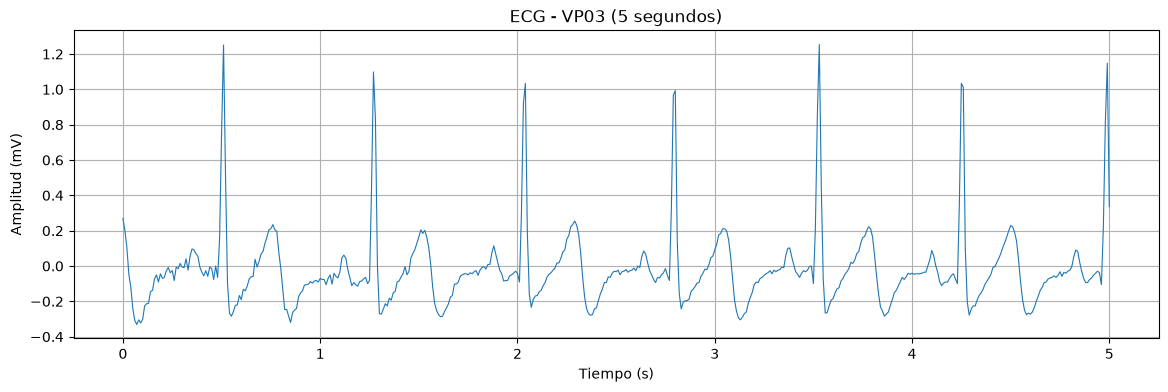

REGISTRO:  VP05
CANTIDAD DE MUESTRAS:  232111
DURACIÓN (en segundos):  2321.11  [s]
DURACIÓN (en minutos):  38.69  [min]
AMPLITUD MÁXIMA:  1.4560546875  [mV]
AMPLITUD MÍNIMA:  -0.6767578125  [mV]


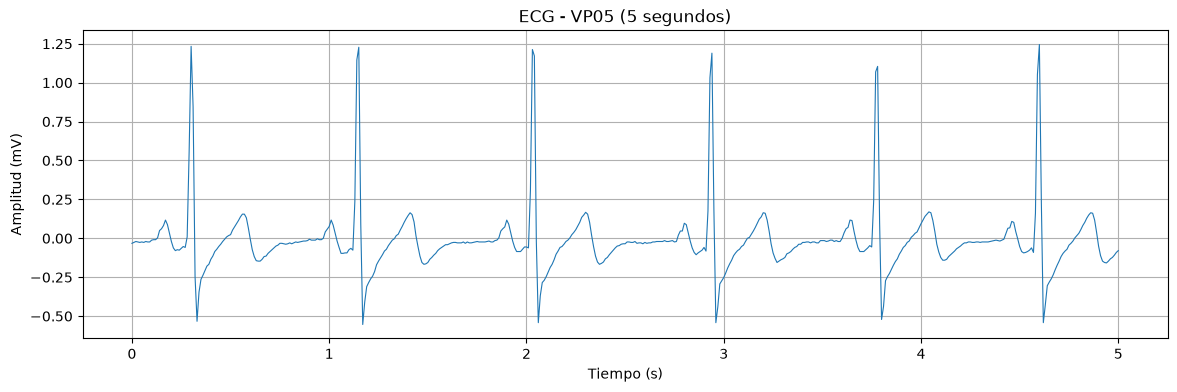

REGISTRO:  VP06
CANTIDAD DE MUESTRAS:  208139
DURACIÓN (en segundos):  2081.39  [s]
DURACIÓN (en minutos):  34.69  [min]
AMPLITUD MÁXIMA:  1.453125  [mV]
AMPLITUD MÍNIMA:  -0.9697265625  [mV]


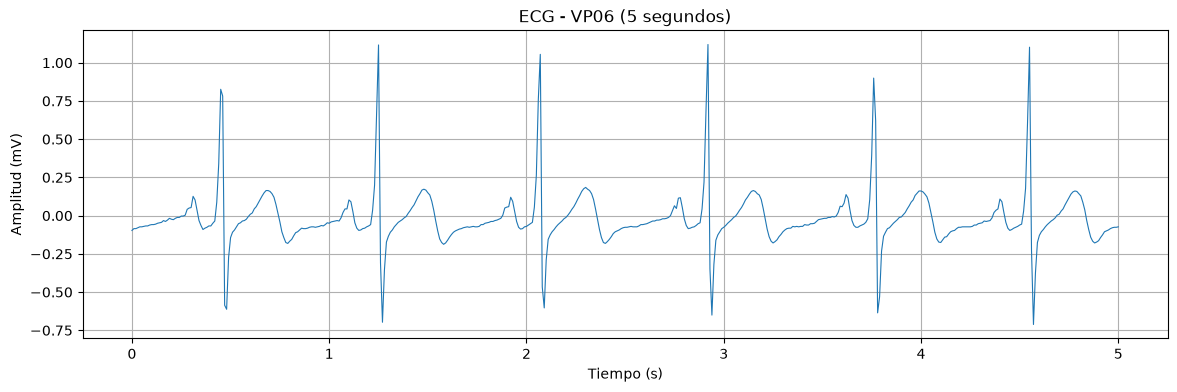

In [25]:
# #Cargo distintos registros
registros = ["VP03","VP05", "VP06"]

for r in registros:
    datos= cargar_ECG_offline(r)
    nmuestras = len(datos["tiempo"])
    duracion = nmuestras/fs
    print("==============")
    print("REGISTRO: ", r)
    print("==============")
    print("CANTIDAD DE MUESTRAS: ", nmuestras)
    print("DURACIÓN (en segundos): ", duracion," [s]")
    print("DURACIÓN (en minutos): ", f"{duracion / 60:.2f}", " [min]")
    print("AMPLITUD MÁXIMA: ", datos["voltaje"].max(), " [mV]")
    print("AMPLITUD MÍNIMA: ", datos["voltaje"].min(), " [mV]")
    graficar_ECG(datos, r, 5)



Graficamos un registro en distintas escalas temporales:

REGISTRO  VP03


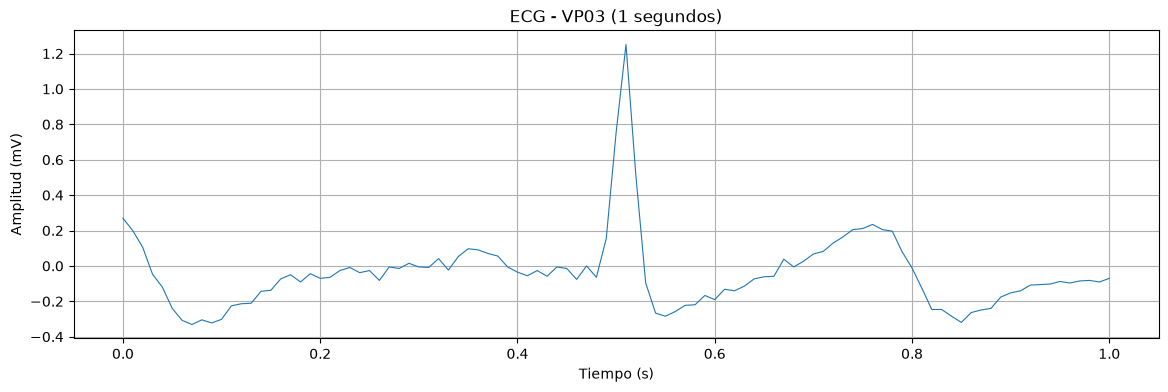

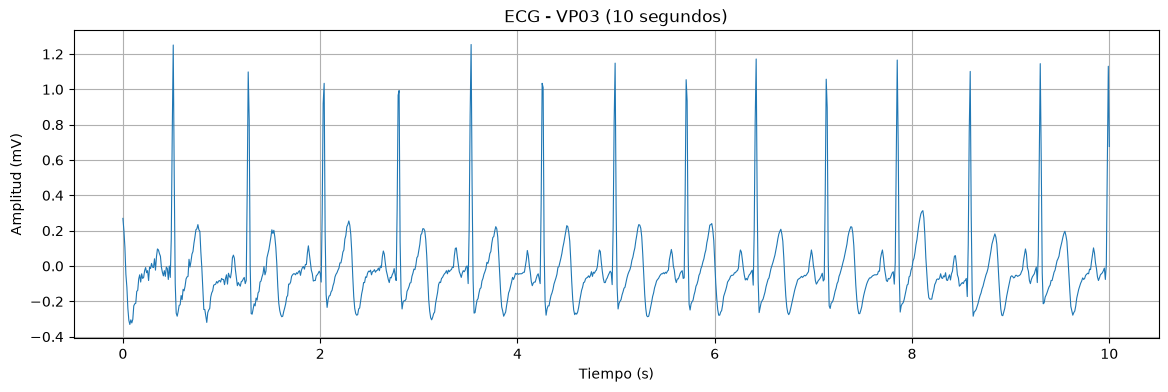

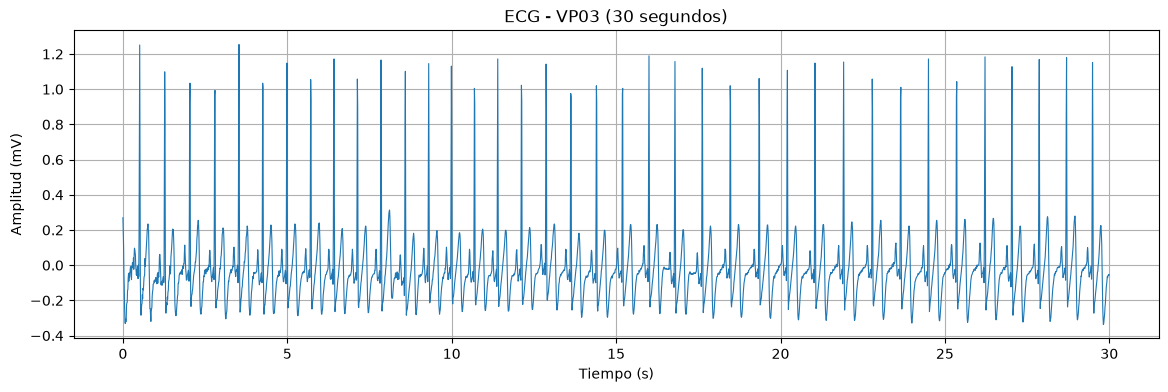

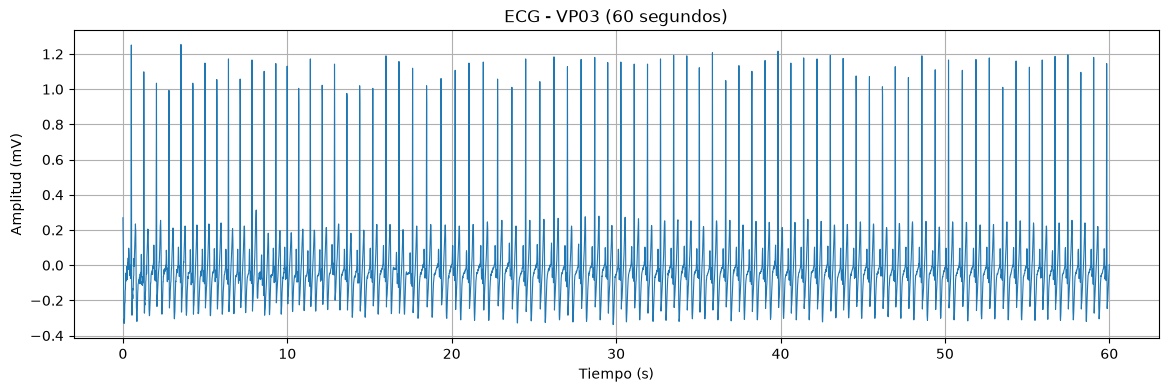

REGISTRO  VP05


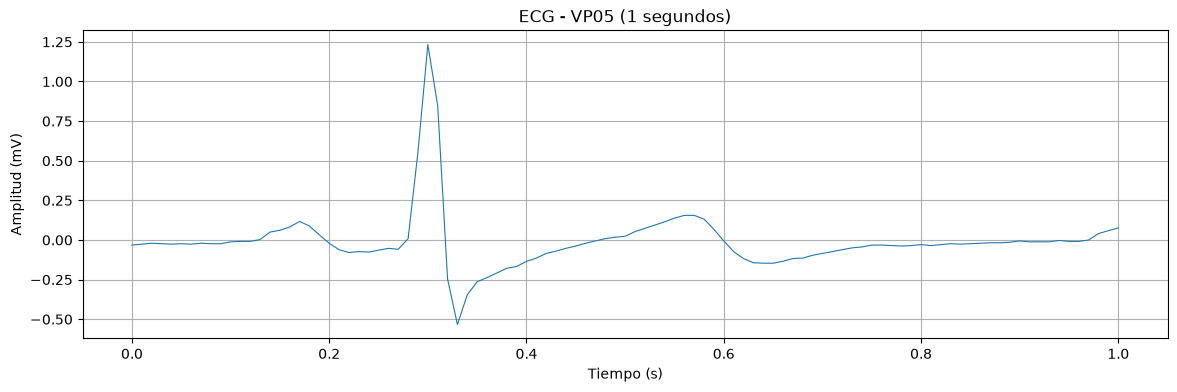

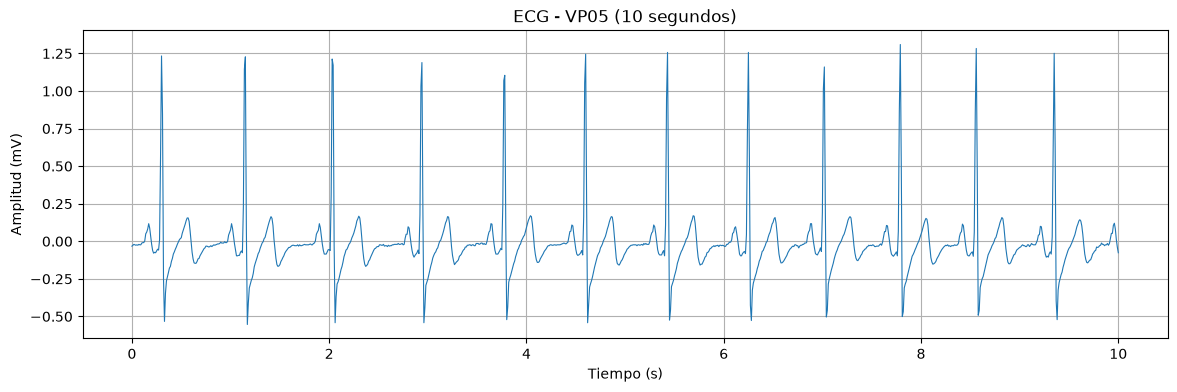

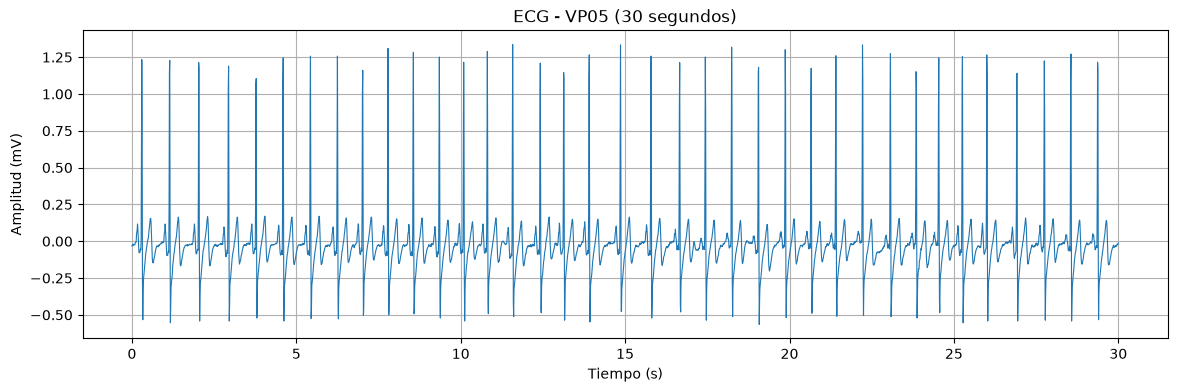

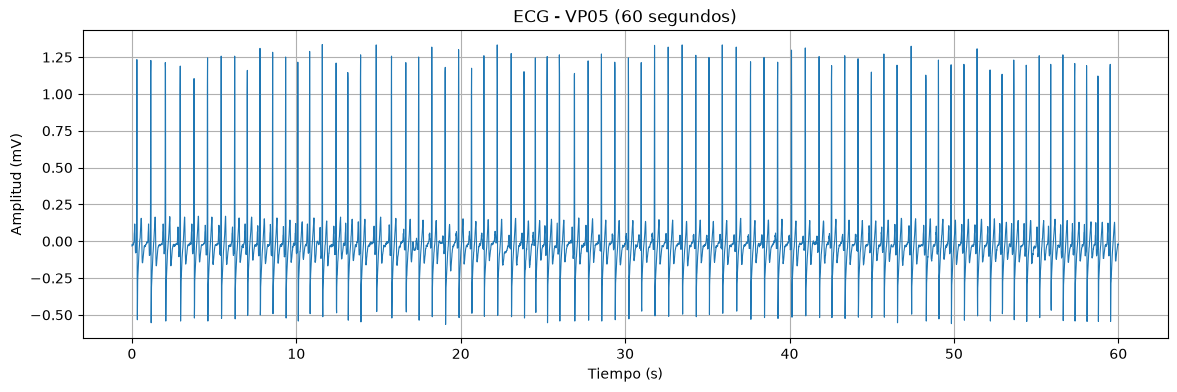

REGISTRO  VP06


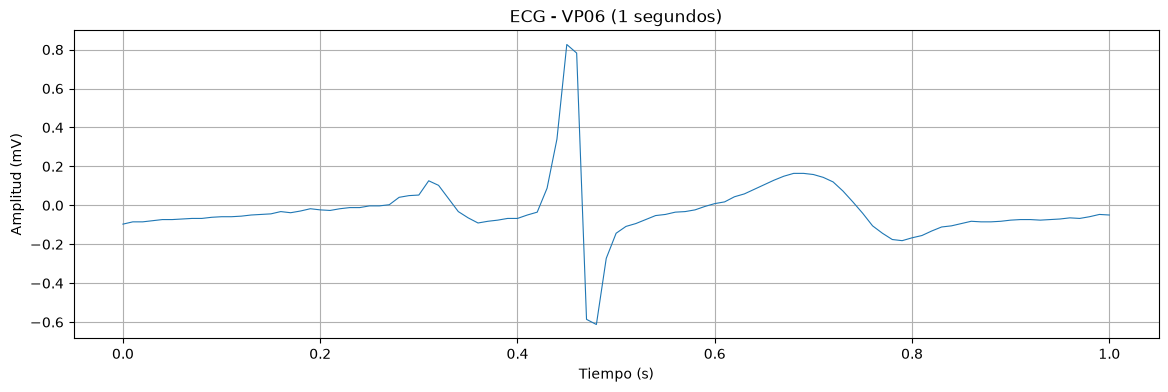

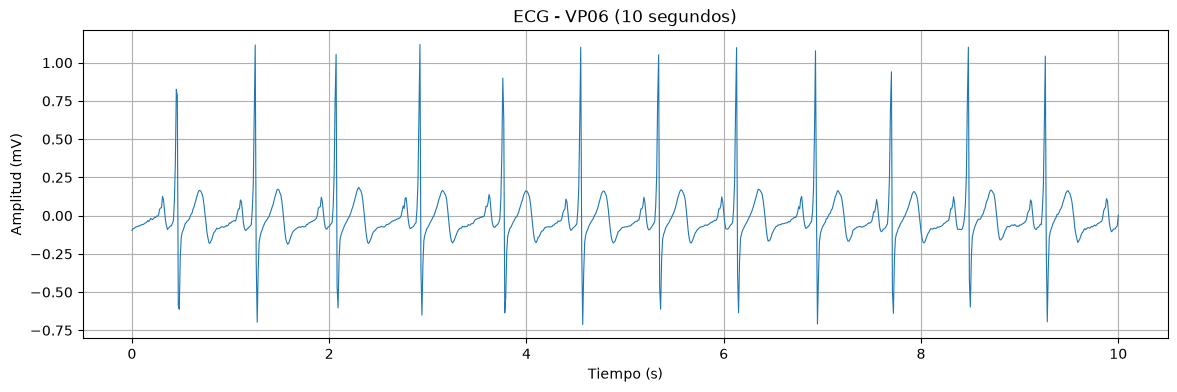

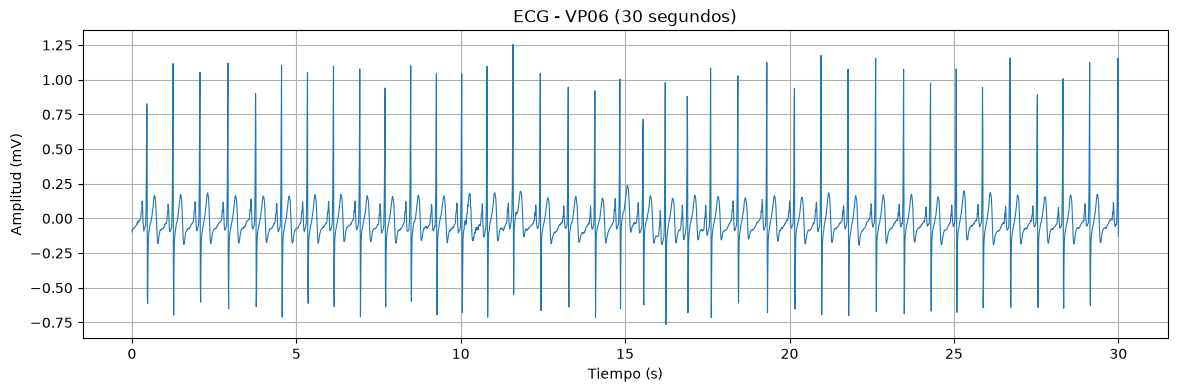

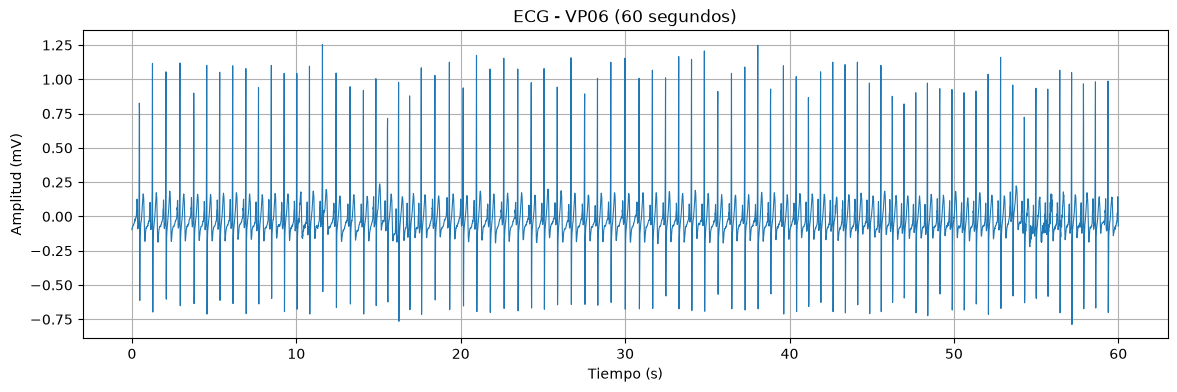

REGISTRO  VP27


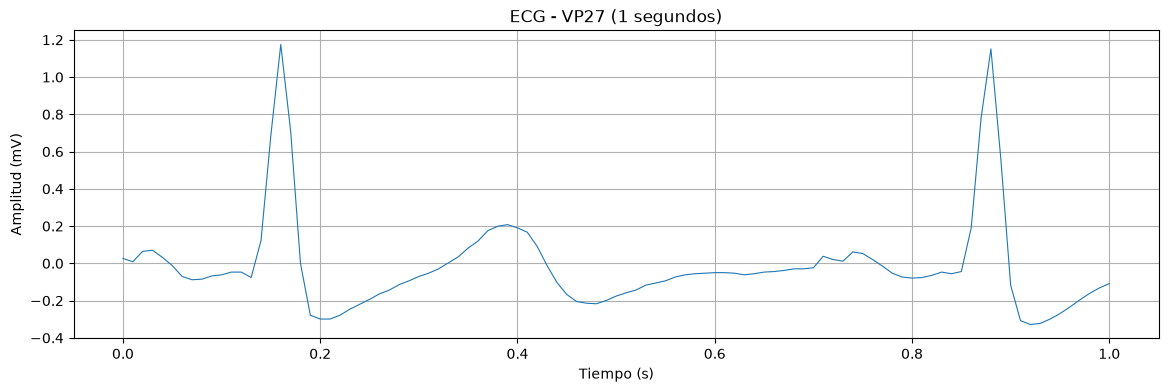

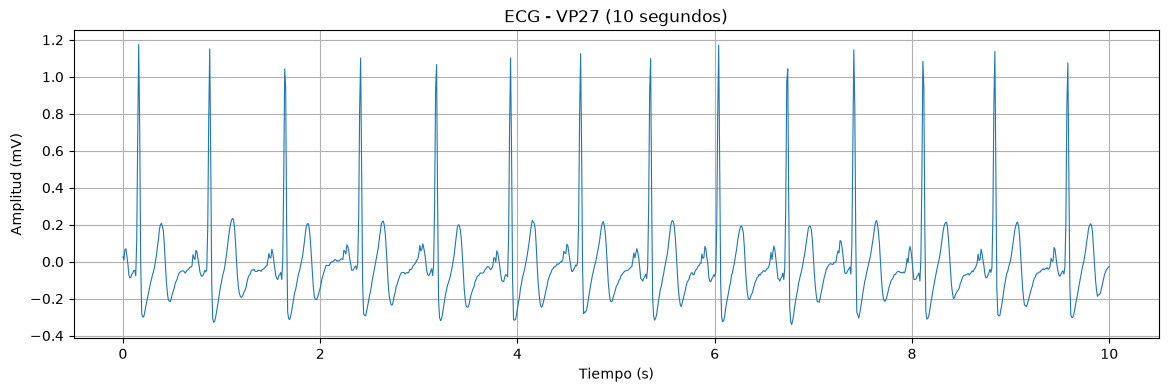

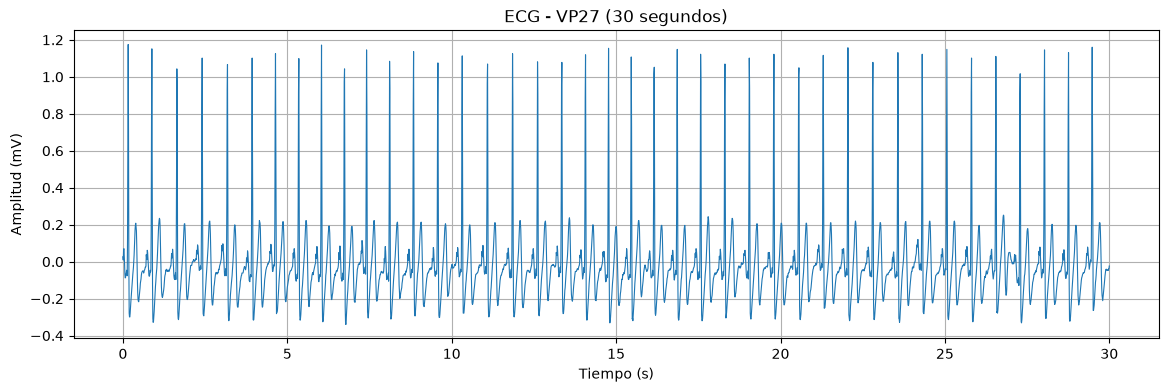

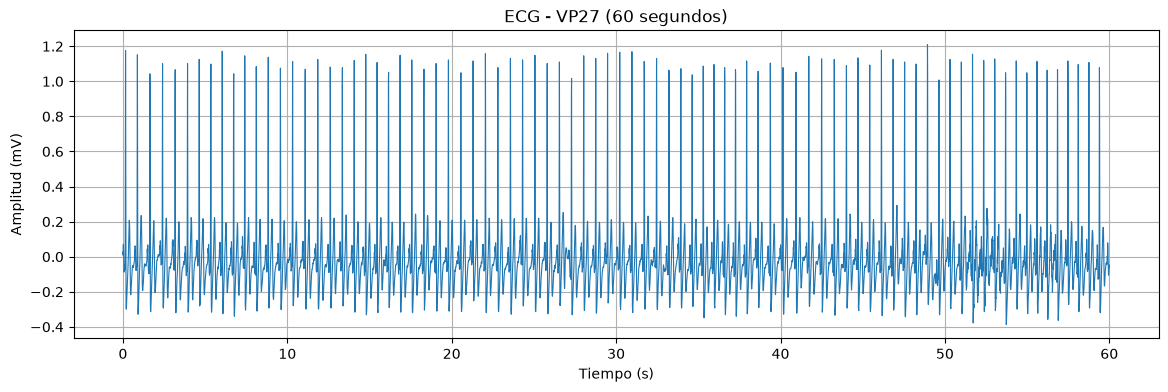

In [29]:
registros = ["VP03","VP05", "VP06","VP27"]
tiempos = (1,10,30,60)

for r in registros:    
    print("=======================")
    print("REGISTRO ", r)
    for t in tiempos:
        datos = cargar_ECG_offline(r)
        graficar_ECG(datos,r,t)
        

Observaciones:
* Los segmentos isoeléctricos se encuentran en general por debajo de 0V.
* En algunos segmentos hay ruido de alta frecuencia, como al inicio del registro VP03.

Igualmente, en general el SNR es alto, probablemente debido a que el sistema de adquisición utilizado incorpora etapas de filtrado analógico.

el registro 27 tiene deriva evidente y hay artefactos de movimiento, asi que estaria bueno mostrarlos aca
